# 02 · Predicting the 2027 season: Plackett–Luce + Monte Carlo

**Goal:** before a single 2027 car has turned a wheel, estimate each driver's chance of winning the 2027 championship.

Notebook 01 looked at one race at a time and scored each driver separately. A season needs more: a model of the **whole finishing order** of every race, and an honest account of everything that can change over a winter.

**The plan**
1. **Measure** every driver's strength in every season with a **Plackett–Luce** model (from scratch).
2. **Learn** how much of that strength carries into the next season: the car, the driver, rookies.
3. **Measure the surprise**: how far teams and drivers typically move against that prediction.
4. **Simulate** 2027 ten thousand times and count the outcomes.
5. **Backtest** the whole method on 2016–2024 before trusting it with 2027.

Two traps turned up while building this notebook. They're both kept in, because they're the most useful lessons in it.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import check_grad, minimize
from scipy.stats import spearmanr

DB = next(p for p in [Path("../data/warehouse.db"), Path("data/warehouse.db")] if p.exists())
with sqlite3.connect(DB) as con:
    df = pd.read_sql('''
        SELECT season, round, race_key, driver_ref, constructor_ref,
               target_position_order AS pos, target_points_std AS pts,
               target_status_category IN ('finished', 'lapped') AS finished
        FROM ml_driver_race
        WHERE season >= 2013 AND target_did_start = 1''', con)

# teams that changed name: map every name to one lineage, so a car's form carries over the rename
LINEAGE = {"lotus_f1": "enstone", "renault": "enstone", "alpine": "enstone",
           "force_india": "silverstone", "racing_point": "silverstone", "aston_martin": "silverstone",
           "toro_rosso": "faenza", "alphatauri": "faenza", "rb": "faenza",
           "sauber": "hinwil", "alfa": "hinwil", "audi": "hinwil",
           "marussia": "banbury", "manor": "banbury"}
df["team"] = df.constructor_ref.map(LINEAGE).fillna(df.constructor_ref)

LAST = df.season.max()
print(f"{len(df):,} starts, seasons {df.season.min()}-{LAST}; latest data: {LAST} round {df[df.season == LAST]['round'].max()}")

5,378 starts, seasons 2013-2026; latest data: 2026 round 17


## 1 · Plackett–Luce: a model of a whole finishing order

Give every driver a **strength** $s$. A race result is then read as a series of picks:

1. The **winner** is picked from all drivers, each with probability $\dfrac{e^{s_i}}{\sum_{\text{all}} e^{s_j}}$
2. **P2** is picked the same way from the drivers who are left
3. … and so on down the order.

The probability of the whole result is the product of those picks. **Fitting** means finding the strengths that make the real results as likely as possible (*maximum likelihood*). Only differences matter: adding 1 to everyone changes nothing, so we centre the strengths on 0.

As a rule of thumb, a gap of **1.0** in strength means the stronger driver is $e^1 ≈ 2.7×$ as likely to be picked first.

The function returns the loss **and its gradient** (the direction to move each strength). The optimiser uses the gradient to find the best strengths quickly. A hand-written gradient is easy to get wrong, so the next cell checks it against a numerical estimate.

In [2]:
def pl_neg_log_likelihood(s, orders, ridge):
    loss, grad = ridge / 2 * s @ s, ridge * s      # ridge: a small pull towards 0, so a driver with one race stays finite
    for o in orders:                               # o = driver indices in finishing order
        x = s[o]
        e = np.exp(x - x.max())                    # subtracting the max keeps exp() from overflowing
        remaining = np.cumsum(e[::-1])[::-1]       # at each pick: total exp(strength) of drivers still unplaced
        loss -= (np.log(e) - np.log(remaining)).sum()
        np.subtract.at(grad, o, 1 - e * np.cumsum(1 / remaining))
    return loss, grad


def fit_pl(races, ridge=0.05):
    # Plackett-Luce strengths. races: lists of driver_ref in finishing order, winner first.
    drivers = sorted({d for race in races for d in race})
    idx = {d: i for i, d in enumerate(drivers)}
    orders = [np.array([idx[d] for d in race]) for race in races]
    res = minimize(pl_neg_log_likelihood, np.zeros(len(drivers)), args=(orders, ridge), jac=True, method="L-BFGS-B")
    return pd.Series(res.x - res.x.mean(), index=drivers)


rng = np.random.default_rng(1)
toy = [rng.permutation(6) for _ in range(5)]
err = check_grad(lambda s: pl_neg_log_likelihood(s, toy, 0.05)[0],
                 lambda s: pl_neg_log_likelihood(s, toy, 0.05)[1], rng.normal(size=6))
print(f"gradient check: {err:.1e}  (tiny = the hand-written gradient is right)")

gradient check: 3.2e-07  (tiny = the hand-written gradient is right)


## 2 · Trap #1: retirements are not "slow"

The first version fed the model **every starter**, in classified order. A driver who retired is listed at the back, so the model read each DNF as *"lost to the entire field"*. Several DNFs were enough to sink a front-runner.

Compare the two versions on the latest season:

In [3]:
def season_races(season, finishers_only=True):
    part = df[df.season == season]
    if finishers_only:
        part = part[part.finished == 1]
    return [race.sort_values("pos").driver_ref.tolist() for _, race in part.groupby("race_key")]


latest = df[df.season == LAST]
compare = pd.DataFrame({
    "points": latest.groupby("driver_ref").pts.sum(),
    "DNFs": latest.groupby("driver_ref").finished.apply(lambda f: int((f == 0).sum())),
    "strength: all starters": fit_pl(season_races(LAST, finishers_only=False)),
    "strength: finishers only": fit_pl(season_races(LAST)),
})
compare.sort_values("points", ascending=False).head(8).style.format(precision=2)

,points,DNFs,strength: all starters,strength: finishers only
antonelli,309,1,1.71,2.58
russell,204,3,0.28,1.85
hamilton,202,1,1.05,2.33
max_verstappen,201,4,0.03,2.66
leclerc,181,3,0.66,2.27
norris,168,3,0.59,2.19
piastri,117,1,0.73,1.08
hadjar,97,2,0.10,1.32


The fix splits each race into **two separate questions**:

- **Does the driver finish?** That's reliability and crashes, modelled as a retirement rate.
- **Among the finishers, in what order?** That's pace, modelled by Plackett–Luce.

From here on, strengths are fitted on **finishers only**, and retirements come back in the simulation.

## 3 · Stage 1: a strength for every driver, every season

Each season is also fitted a second time on its **odd-numbered** races and its **even-numbered** races. Section 4 uses that to measure how precise the strengths are.

In [4]:
rows = []
for season, part in df.groupby("season"):
    races = season_races(season)
    info = part.groupby("driver_ref").agg(races=("race_key", "size"), team=("team", lambda t: t.mode()[0]),
                                          pts=("pts", "sum"))
    info["strength"] = fit_pl(races)
    info["half_diff"] = fit_pl(races[0::2]) - fit_pl(races[1::2])
    info["season"] = season
    rows.append(info.reset_index())
strengths = pd.concat(rows, ignore_index=True).dropna(subset=["strength"])   # drops drivers who never finished

# a team's strength = its drivers' strengths, weighted by races
team_strength = (strengths.groupby(["season", "team"])
                 .apply(lambda g: np.average(g.strength, weights=g.races), include_groups=False)
                 .rename("team_strength"))

strengths[strengths.season == LAST].sort_values("strength", ascending=False).head(10)[
    ["driver_ref", "team", "races", "pts", "strength"]].style.format({"strength": "{:.2f}"})

,driver_ref,team,races,pts,strength
283,max_verstappen,red_bull,17,201,2.66
271,antonelli,mercedes,17,309,2.58
279,hamilton,ferrari,17,202,2.33
282,leclerc,ferrari,17,181,2.27
284,norris,mclaren,16,168,2.19
288,russell,mercedes,17,204,1.85
278,hadjar,red_bull,14,97,1.32
287,piastri,mclaren,15,117,1.08
281,lawson,faenza,17,68,0.42
277,gasly,enstone,17,39,0.12


## 4 · How precise is a season's strength?

If the strengths were perfect, the odd-race fit and the even-race fit would agree. They don't. Each half has twice the noise of the full season, and their difference has twice that again, so

$$\text{noise of a full-season strength}^2 ≈ \frac{\text{var(odd − even)}}{4}$$

This number matters later: some of the season-to-season "surprise" is just this measurement noise, not real change.

In [5]:
reliable = strengths[strengths.races >= 10]
print(f"measurement noise of one season's strength:  ±{np.sqrt(reliable.half_diff.var() / 4):.2f}")
print(f"real spread of strengths between drivers:    ±{reliable.strength.std():.2f}")

measurement noise of one season's strength:  ±0.48
real spread of strengths between drivers:    ±1.85


## 5 · Stage 2: what carries over the winter?

For each driver in season *Y*, three features come from season *Y − 1*:

| Feature | Meaning |
|---|---|
| `team_prev` | how strong **this year's team** was last year: the car |
| `driver_edge` | how much better the driver was than **their own teammate** last year: the driver. It travels with them if they switch teams. |
| `rookie` | 1 if the driver has no season to judge by |

A linear regression predicts this season's strength from them. Each weight answers a question. A `team_prev` weight of 0.75 would mean **three quarters of a car's advantage survives the winter**, and the rest fades towards the pack.

231 driver-seasons with a previous season to learn from: 2014-2024


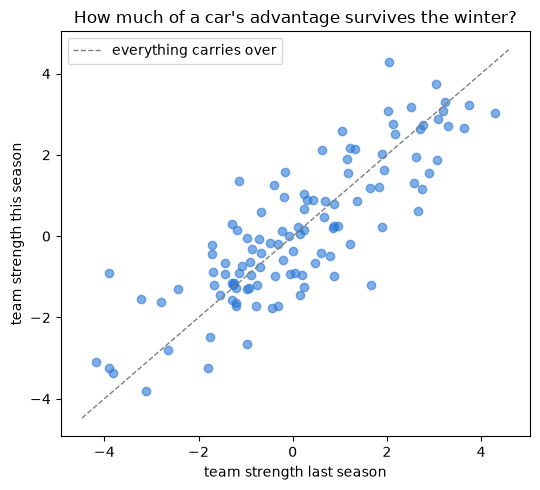

In [6]:
def features(lineup, prev_season):
    # Pre-season features for each (driver_ref, team) row of lineup, taken from prev_season.
    prev = strengths[strengths.season == prev_season].set_index("driver_ref")
    teams_prev = team_strength.loc[prev_season]
    out = lineup.copy()
    out["team_prev"] = out.team.map(teams_prev).fillna(teams_prev.min())    # a brand-new team starts at the back
    known = out.driver_ref.isin(prev.index[prev.races >= 3])
    p = prev.reindex(out.driver_ref)
    out["driver_edge"] = np.where(known, p.strength.to_numpy() - p.team.map(teams_prev).to_numpy(), 0.0)
    out["rookie"] = (~known).astype(float)
    return out


FEATURES = ["team_prev", "driver_edge", "rookie"]
seasons = sorted(strengths.season.unique())
pairs = pd.concat([features(strengths[(strengths.season == y) & (strengths.races >= 5)], y - 1)
                   for y in seasons if y - 1 in seasons], ignore_index=True)
print(f"{len(pairs)} driver-seasons with a previous season to learn from: {pairs.season.min()}-{pairs.season.max()}")

teams = pairs.groupby(["season", "team"]).agg(last_year=("team_prev", "first"), this_year=("strength", "mean"))
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(teams.last_year, teams.this_year, alpha=0.6, color="#2a78d6")
lim = [teams.min().min() - 0.3, teams.max().max() + 0.3]
ax.plot(lim, lim, ls="--", color="grey", lw=1, label="everything carries over")
ax.set_xlabel("team strength last season")
ax.set_ylabel("team strength this season")
ax.set_title("How much of a car's advantage survives the winter?")
ax.legend()
plt.tight_layout()
plt.show()

## 6 · Trap #2: don't count the noise twice

After the regression, what's left over is the **surprise**: how far each team and driver landed from the prediction. Teammates share a car, so the surprise is split in two:

- **team surprise**: the whole car moved (a good or bad winter at the factory)
- **driver surprise**: one driver moved against their teammate

The first version used the raw leftovers. But part of each leftover is just the **measurement noise from section 4**, and the simulation already adds race-to-race luck on top. Counting that noise twice made every season look more random than it is. The function below subtracts it.

In [7]:
def fit_carryover(train):
    # Regression weights + team and driver surprise, learned only from the seasons in train.
    X = np.c_[np.ones(len(train)), train[FEATURES].to_numpy()]
    beta, *_ = np.linalg.lstsq(X, train.strength.to_numpy(), rcond=None)
    r = train.assign(resid=train.strength.to_numpy() - X @ beta)
    known = strengths[(strengths.races >= 10) & (strengths.season <= train.season.max())]
    noise2 = known.half_diff.var() / 4                                    # measurement noise, section 4
    team_mean = r.groupby(["season", "team"]).resid.transform("mean")
    var_within = (r.resid - team_mean).var()                              # teammate vs teammate
    var_team = r.groupby(["season", "team"]).resid.mean().var()           # whole car
    sigma_driver = np.sqrt(max(2 * var_within - noise2, 0))
    sigma_team = np.sqrt(max(var_team - sigma_driver**2 / 2 - noise2 / 2, 0))
    return pd.Series(beta, index=["intercept"] + FEATURES), sigma_team, sigma_driver


def predict(beta, part):
    return (beta["intercept"] + part[FEATURES].to_numpy() @ beta[FEATURES].to_numpy())


beta, sigma_team, sigma_driver = fit_carryover(pairs)
print(beta.round(2).to_string())
print(f"\nteam surprise:   ±{sigma_team:.2f}   <- how far a whole car typically moves vs the prediction")
print(f"driver surprise: ±{sigma_driver:.2f}")

intercept      0.08
team_prev      0.76
driver_edge    0.47
rookie        -0.43

team surprise:   ±0.85   <- how far a whole car typically moves vs the prediction
driver surprise: ±0.33


## 7 · Simulating a season

**The Gumbel trick.** Drawing a Plackett–Luce finishing order sounds fiddly (pick the winner, remove them, pick again…). There's a shortcut: add random **Gumbel** noise to every strength and sort. The resulting order follows Plackett–Luce exactly. A quick check:

In [8]:
s = np.array([1.0, 0.5, 0.0])
winners = np.argmax(s + np.random.default_rng(0).gumbel(size=(100_000, 3)), axis=1)
print("win share, simulated:", (np.bincount(winners) / len(winners)).round(3))
print("win share, formula:  ", (np.exp(s) / np.exp(s).sum()).round(3))

win share, simulated: [0.505 0.31  0.185]
win share, formula:   [0.506 0.307 0.186]


One simulated season:

1. **The winter.** Each team's car lands somewhere around its prediction (team surprise), and each driver around theirs (driver surprise). These are drawn once and stay fixed for the whole season.
2. **Every race.** Each driver retires with the recent retirement rate. The finishers are ordered by strength + Gumbel noise, and points are awarded 25-18-15-12-10-8-6-4-2-1.

That's repeated 10,000 times. All the seasons are simulated at once as one big array, so it takes a few seconds.

In [9]:
POINTS = np.array([25, 18, 15, 12, 10, 8, 6, 4, 2, 1])
dnf_rate_by_season = 1 - df.groupby("season").finished.mean()


def recent_dnf_rate(before):
    return dnf_rate_by_season[dnf_rate_by_season.index < before].tail(3).mean()


def simulate_season(lineup, mu, sigma_team, sigma_driver, n_races, dnf_rate, n_sims=10_000, seed=0):
    # Points per driver in n_sims simulated seasons -> array (n_sims, n_drivers).
    rng = np.random.default_rng(seed)
    n = len(lineup)
    _, team_idx = np.unique(lineup.team.to_numpy(), return_inverse=True)
    strength = (mu[None, :]
                + rng.normal(0, sigma_team, (n_sims, team_idx.max() + 1))[:, team_idx]   # 1. the winter: cars
                + rng.normal(0, sigma_driver, (n_sims, n)))                              #    ... and drivers
    perf = strength[:, None, :] + rng.gumbel(size=(n_sims, n_races, n))                  # 2. every race
    perf[rng.random(perf.shape) < dnf_rate] = -np.inf                                    #    retirements
    rank = np.argsort(np.argsort(-perf, axis=2), axis=2)                                 #    0 = winner
    pts = np.where(rank < len(POINTS), POINTS[np.minimum(rank, len(POINTS) - 1)], 0)
    pts[np.isinf(perf)] = 0
    return pts.sum(axis=1)

## 8 · Backtest: would this have worked before?

For each season from 2016 to 2024, everything is learned **only from earlier seasons** (*walk-forward*). Then the season is simulated with its real driver line-up and compared with what happened. Three versions are compared:

- **last year repeats**: every driver keeps last season's strength, with no winter surprise. This is the simplest baseline.
- **model, no surprise**: the regression's prediction, but the winter is assumed to change nothing
- **model**: the full version, with team and driver surprise

How they're scored:

- **P(actual champion)**: the probability given in advance to the driver who really won
- **champion log score**: the log of that probability, averaged. Closer to 0 is better, and it punishes being confidently wrong.
- **80% range coverage**: how often a driver's real points landed inside their predicted 80% range. **It should be close to 80%.** Much lower means the forecast is overconfident.
- **order correlation**: how well the expected points ranked the whole field (1 = perfect)

Drivers who missed races are scaled up to a full season, so they're compared fairly.

In [10]:
rows = []
for y in range(2016, LAST + 1):
    if y not in pairs.season.values:
        continue
    beta_y, s_team, s_drv = fit_carryover(pairs[pairs.season < y])
    field = pairs[pairs.season == y].reset_index(drop=True)
    n_races = df[df.season == y].race_key.nunique()
    actual = field.pts.to_numpy() * n_races / field.races.to_numpy()     # missed races scaled to a full season
    champion = field.pts.idxmax()
    for method, mu, st, sd in [("last year repeats", (field.team_prev + field.driver_edge).to_numpy(), 0.0, 0.0),
                               ("model, no surprise", predict(beta_y, field), 0.0, 0.0),
                               ("model", predict(beta_y, field), s_team, s_drv)]:
        pts = simulate_season(field, mu, st, sd, n_races, recent_dnf_rate(y), n_sims=4000)
        lo_y, hi_y = np.percentile(pts, [10, 90], axis=0)
        p_champ = (pts.argmax(axis=1) == champion).mean()
        rows.append({"season": y, "method": method, "champion": field.driver_ref[champion],
                     "favourite": field.driver_ref[pts.mean(axis=0).argmax()],
                     "P(actual champion)": p_champ, "champion log score": np.log(max(p_champ, 1 / len(pts))),
                     "80% range coverage": ((actual >= lo_y) & (actual <= hi_y)).mean(),
                     "order correlation": spearmanr(pts.mean(axis=0), actual).statistic})
backtest = pd.DataFrame(rows)
methods = ["last year repeats", "model, no surprise", "model"]

by_season = backtest.pivot(index="season", columns="method", values="P(actual champion)")[methods]
by_season.insert(0, "champion", backtest.groupby("season").champion.first())
display(by_season.style.format("{:.0%}", subset=methods).set_caption("P(actual champion), given before the season"))
(backtest.groupby("method")[["P(actual champion)", "champion log score", "80% range coverage", "order correlation"]]
 .mean().loc[methods].style.format({"P(actual champion)": "{:.0%}", "champion log score": "{:.2f}",
                                    "80% range coverage": "{:.0%}", "order correlation": "{:.2f}"}))

method,champion,last year repeats,"model, no surprise",model
season,,,,
2016,rosberg,1%,50%,26%
2017,hamilton,51%,46%,27%
2018,hamilton,18%,23%,19%
2019,hamilton,75%,40%,28%
2020,hamilton,30%,42%,26%
2021,max_verstappen,33%,15%,19%
2022,max_verstappen,85%,63%,37%
2023,max_verstappen,79%,58%,37%
2024,max_verstappen,100%,99%,74%


,P(actual champion),champion log score,80% range coverage,order correlation
method,,,,
last year repeats,52%,-1.08,45%,0.82
"model, no surprise",49%,-0.85,46%,0.82
model,32%,-1.21,72%,0.82


## 9 · 2027

**The line-up.** By default, every driver stays where they were at the latest race. Edit `LINEUP_CHANGES` to move a driver (`"driver_ref": "constructor_ref"`), add a rookie under a new name, or remove someone with `None`, then re-run from here.

The 2027 calendar isn't published yet, so `N_RACES` is a guess.

In [11]:
N_RACES = 24
LINEUP_CHANGES = {
    # "hadjar": "rb",            # move a driver
    # "new_rookie": "williams",  # a new name is treated as a rookie
    # "alonso": None,            # retire a driver
}

last_round = df[(df.season == LAST) & (df["round"] == df[df.season == LAST]["round"].max())]
seats = dict(zip(last_round.driver_ref, last_round.constructor_ref)) | LINEUP_CHANGES
lineup = pd.DataFrame(seats.items(), columns=["driver_ref", "constructor_ref"]).dropna().reset_index(drop=True)
lineup["team"] = lineup.constructor_ref.map(LINEAGE).fillna(lineup.constructor_ref)

field = features(lineup, LAST)
field["predicted strength"] = predict(beta, field)
dnf_rate = recent_dnf_rate(LAST + 1)
pts = simulate_season(field, field["predicted strength"].to_numpy(), sigma_team, sigma_driver, N_RACES, dnf_rate)
print(f"{len(field)} drivers · {N_RACES} races · retirement rate {dnf_rate:.0%} · {len(pts):,} simulated seasons")

22 drivers · 24 races · retirement rate 15% · 10,000 simulated seasons


In [12]:
final_pos = np.argsort(np.argsort(-pts, axis=1), axis=1) + 1
lo, hi = np.percentile(pts, [10, 90], axis=0)
drivers = pd.DataFrame({
    "driver": field.driver_ref, "team": field.constructor_ref,
    "title": (final_pos == 1).mean(axis=0), "top 3": (final_pos <= 3).mean(axis=0),
    "expected points": pts.mean(axis=0),
    "likely range (80%)": [f"{a:.0f}–{b:.0f}" for a, b in zip(lo, hi)],
}).sort_values("expected points", ascending=False).reset_index(drop=True)
drivers.index += 1
drivers.style.format({"title": "{:.0%}", "top 3": "{:.0%}", "expected points": "{:.0f}"})

,driver,team,title,top 3,expected points,likely range (80%)
1,max_verstappen,red_bull,22%,48%,244,122–366
2,antonelli,mercedes,20%,48%,243,122–364
3,hamilton,ferrari,15%,43%,233,114–353
4,leclerc,ferrari,14%,42%,230,111–350
5,norris,mclaren,12%,35%,210,93–332
6,russell,mercedes,8%,32%,208,93–327
7,hadjar,red_bull,4%,21%,179,71–299
8,piastri,mclaren,3%,15%,158,58–272
9,lawson,rb,1%,5%,99,24–195
10,gasly,alpine,1%,3%,86,18–173


In [13]:
team_pts = pd.DataFrame(pts, columns=field.constructor_ref).T.groupby(level=0).sum().T
constructors = pd.DataFrame({"title": team_pts.idxmax(axis=1).value_counts(normalize=True),
                             "expected points": team_pts.mean()}).fillna(0)
constructors = constructors.sort_values("expected points", ascending=False)
constructors.style.format({"title": "{:.0%}", "expected points": "{:.0f}"})

,title,expected points
ferrari,31%,463
mercedes,29%,450
red_bull,23%,423
mclaren,14%,368
rb,1%,181
alpine,1%,154
audi,1%,143
haas,0%,100
williams,0%,69
aston_martin,0%,42


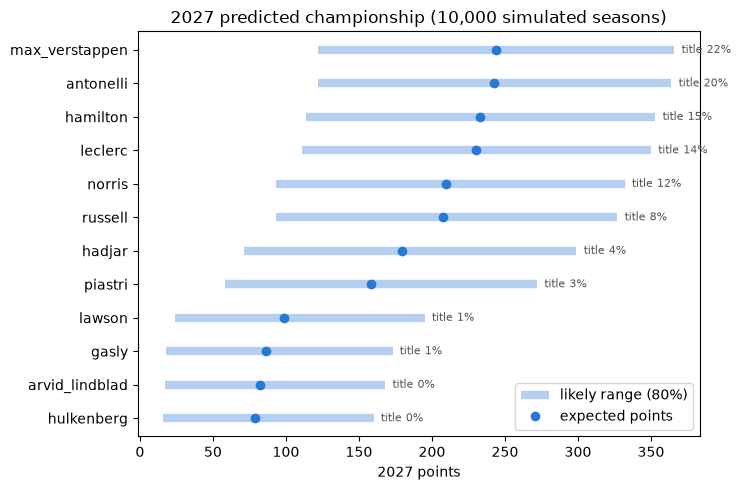

In [14]:
top = drivers.head(12).iloc[::-1]
order = [list(field.driver_ref).index(d) for d in top.driver]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.hlines(top.driver, lo[order], hi[order], color="#2a78d6", lw=6, alpha=0.35, label="likely range (80%)")
ax.plot(top["expected points"], top.driver, "o", color="#2a78d6", label="expected points")
for y, (p, x) in enumerate(zip(top.title, hi[order])):
    ax.text(x + 5, y, f"title {p:.0%}", va="center", fontsize=8, color="#555")
ax.set_xlabel("2027 points")
ax.set_title(f"2027 predicted championship ({len(pts):,} simulated seasons)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10 · Takeaways

Numbers from the first run, with data up to 2026 round 17 (your numbers will move as data is added):

**What the model learned**
- **The car carries over, mostly.** About **three quarters** (0.76) of a team's advantage survives the winter. The rest fades towards the pack.
- **The driver carries over, partly.** About **half** (0.47) of a driver's edge over their teammate shows up again the next year. Part of that edge was luck in the first place.
- **Rookies start about 0.4 behind** what their car alone would suggest.
- **The car is the big unknown.** Team surprise (±0.85) is more than twice the driver surprise (±0.33). Most of what makes a season hard to call happens at the factory over the winter.

**What the backtest says (2016–2024)**

| | P(actual champion) | champion log score | 80% range coverage |
|---|---|---|---|
| last year repeats | 52% | −1.08 | 45% |
| model, no surprise | 49% | **−0.85** | 46% |
| **model** | 32% | −1.21 | **72%** |

- **Two scores, two different answers.** The confident versions score better on "who was champion", because 2016–2024 was mostly won by one dominant car (Mercedes, then Red Bull), so betting heavily on the favourite paid off. Their 80% ranges missed most drivers' real points more than half the time, though. Only the full model's ranges are honest (72%, close to the 80% target, and if anything still slightly too narrow).
- **Choose the metric before looking at the results.** Picking whichever version scored best here would have meant picking the overconfident one, judged on just 9 seasons. That's a classic way to fool yourself.
- **Ranking the field is the easy part.** All three versions order the drivers about equally well (0.82). Where they differ is how *sure* they are.

**2027**
- The model sees **no clear favourite**: the top two are about 1 in 5 each and five drivers are above 10%. 2026 was close at the front, and a winter can reshuffle a close field.
- **The constructors' title is a three-way fight** between Ferrari, Mercedes and Red Bull, with McLaren close behind.
- The 80% ranges are wide (roughly 120–360 points for the favourites). That isn't a flaw. It's the honest size of not knowing what each car will be like.

**Caveats**
- **2026 isn't finished.** These numbers use 17 of its 23 races. After the finale, run `python ingest.py`, then `python warehouse/build_warehouse.py`, then re-run this notebook.
- **2026 was a regulation reset**, so 2027 is year two of the same rules. In the past, the field usually closes up in the second year.
- **The 2027 line-up is assumed unchanged.** Use `LINEUP_CHANGES` as moves are announced.
- **Not modelled:** sprint points, team-specific reliability, development during the season, and the 2025 season (missing from the data).

## 11 · Try it yourself

1. **Line-up changes.** Move a driver to a different team with `LINEUP_CHANGES`. How much does the title chance follow the car, and how much the driver?
2. **The regulation reset.** Leave the reset years (2014, 2017, 2022) out of `pairs` when fitting `fit_carryover`. Does the team surprise shrink? Should 2027 use the smaller value?
3. **Late-season form.** Build `team_prev` from only the last third of the previous season. Does that predict better than the full season?
4. **Team reliability.** Replace the single retirement rate with each team's own rate from last season, pulled towards the average. Does coverage improve?
5. **Calibration plot.** For the backtest, plot predicted title probability against how often it happened, as in notebook 01. With only 9 champions, what can you honestly conclude?